# 13 — Doplňkové analýzy: rank-size, hustota dle kraje, citlivost na k, hranice ČR

Čtyři samostatné doplňky k nb07/nb08, vyžádané při revizi článku na webu:

1. **Kolik obyvatel ČR žije v obcích na -ice** — jedno srovnávací číslo
   (populace -ice obcí / celková populace ČR), ne analýza.
2. **Rank-size (Zipfův) graf** — populace obce vs. pořadí podle velikosti,
   log-log, s referenční čárou ideálního Zipfova rozdělení (sklon -1).
3. **Hustota -ice obcí podle rozlohy kraje** — `plot_region_totals` (nb07)
   ukazuje absolutní počty, které zavádí kvůli různé velikosti krajů; tenhle
   graf normalizuje plochou.
4. **Citlivost prostorové autokorelace (nb08) na volbě k** — `moran_binary_test`
   používá k=6; tenhle graf ukáže, že volba není arbitrární v tom smyslu, že
   by měnila závěr — I zůstává kladné a významné napříč k=4..20.

Navíc: `plot_lisa_map` (nb08) dostala volitelný parametr `boundary` — hranice
ČR se teď vykresluje pod body, aby byla mapa čitelná bez nutnosti znát tvar
republiky nazpaměť.

In [1]:
import sys
from pathlib import Path

project_root = Path("..")
sys.path.insert(0, str(project_root / "src"))

import pandas as pd

from geogram import viz, config, data, morphology

viz.set_style()

DATA = config.PROCESSED_DIR
grammar = pd.read_csv(DATA / "ice_grammar_wiki_v2.csv")
geo = pd.read_csv(DATA / "municipalities_ice_integrated.csv")
df = grammar.drop(columns=["latitude", "longitude"], errors="ignore").merge(geo[["code", "latitude", "longitude"]], on="code", how="left")
df = morphology.add_suffix_column(df)
len(df)

1906

## 1. Kolik obyvatel ČR žije v obcích na -ice?

In [2]:
pop_ice = df["population_total"].sum()
pct = pop_ice / data.CZ_POPULATION_TOTAL_2025
print(f"Populace -ice obcí: {pop_ice:,.0f}")
print(f"Populace ČR (ČSÚ, 1. 1. 2025): {data.CZ_POPULATION_TOTAL_2025:,.0f}")
print(f"Podíl: {pct:.2%}")

Populace -ice obcí: 2,072,757
Populace ČR (ČSÚ, 1. 1. 2025): 10,909,500
Podíl: 19.00%


## 2. Rank-size (Zipfův) graf

Popisný pohled, ne test — má tedy vlastní barvu (INK) místo PRIMARY,
viz `plot_rank_size` docstring. ~1 800 bodů → PNG, ne SVG.

WindowsPath('C:/Users/dobes/Documents/UniversityCodingProject/NewFunnyProjects/GeoGram_sufix-ice/assets/img/geogram/13_rank_size.png')

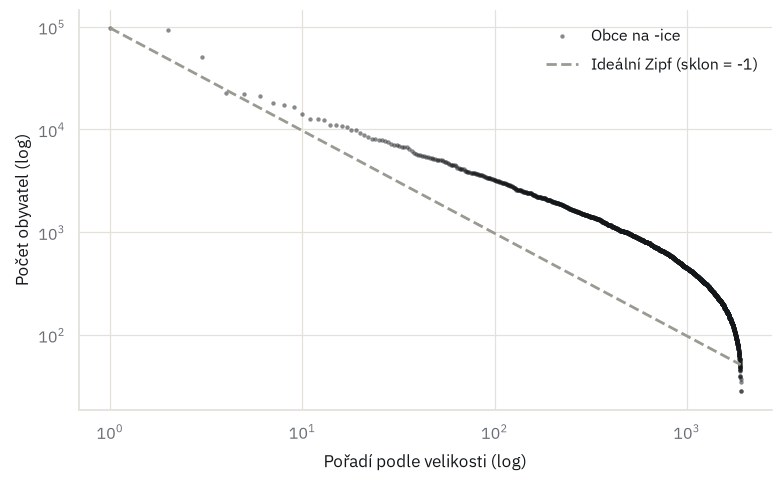

In [3]:
fig = viz.plot_rank_size(df)
viz.save_fig(fig, "13_rank_size", fmt="png")

### 2b. Platí Zipfův zákon opravdu? (férové testování)

Rank-size graf s referenční čárou sklonu -1 vypadá přesvědčivě, ale podle
kritiky Piantadosiho (2014) je to přesně ten typ "důkazu" (OLS na log-log,
vysoké R²), který nic neříká o tom, jestli je mocninné rozdělení skutečně
nejlepší popis dat. Správný postup (Clauset, Shalizi & Newman 2009, balík
`powerlaw`): MLE odhad exponentu s KS-optimálním prahem `x_min`, Monte Carlo
bootstrap GOF test, a Vuongův LRT proti log-normálnímu rozdělení — hlavní
alternativě u velikostí měst (Eeckhout 2004, "Gibrat's law for (all)
cities"). Metodika stejná jako v `FairZipf/src/stats.py`, jen zkrácená na
jednu alternativu (log-normální) místo čtyř — pro krátkou shrnující sekci
na webu stačí ta nejdůležitější.

In [4]:
zipf_result = viz.test_zipf_law(df, n_bootstrap=200)
print(f"alpha = {zipf_result['alpha']:.3f} ± {zipf_result['sigma']:.3f}")
print(f"xmin = {zipf_result['xmin']:.0f}  (n_tail = {zipf_result['n_tail']} / {len(df)} obcí)")
print(f"bootstrap GOF p = {zipf_result['bootstrap_p']:.3f}  ({zipf_result['n_bootstrap']} vzorků)")
print(f"LRT vs. log-normální: R = {zipf_result['lognormal_R']:.4f}, p = {zipf_result['lognormal_p']:.4f}")

alpha = 2.495 ± 0.099
xmin = 1810  (n_tail = 229 / 1906 obcí)
bootstrap GOF p = 0.995  (200 vzorků)
LRT vs. log-normální: R = -0.0517, p = 0.9588


WindowsPath('C:/Users/dobes/Documents/UniversityCodingProject/NewFunnyProjects/GeoGram_sufix-ice/assets/img/geogram/13_zipf_ccdf.svg')

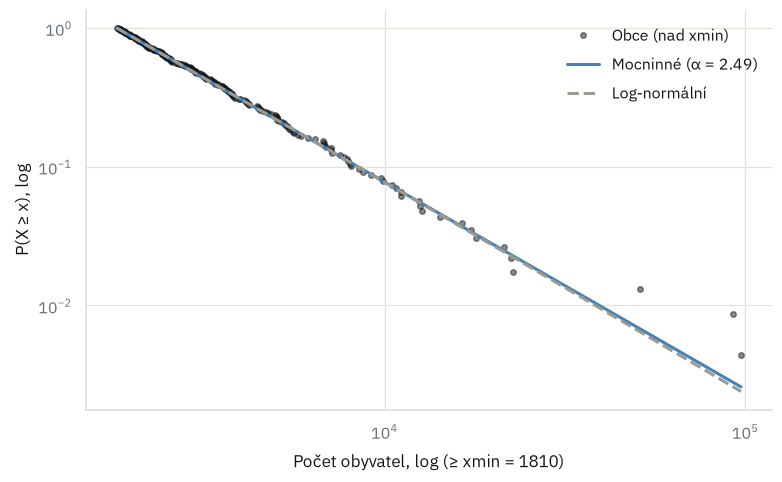

In [5]:
fig = viz.plot_zipf_ccdf(zipf_result["fit"])
viz.save_fig(fig, "13_zipf_ccdf")

## 3. Hustota -ice obcí podle rozlohy kraje

Surové počty (nb07, `plot_region_totals`) vedou Středočeský a Jihomoravský
kraj — částečně jen proto, že jsou plošně největší. Normalizace rozlohou
(Wikidata P2046, cituje ČSÚ) dá jinou odpověď na "kde jich je nejvíc".

WindowsPath('C:/Users/dobes/Documents/UniversityCodingProject/NewFunnyProjects/GeoGram_sufix-ice/assets/img/geogram/13_density_by_kraj.svg')

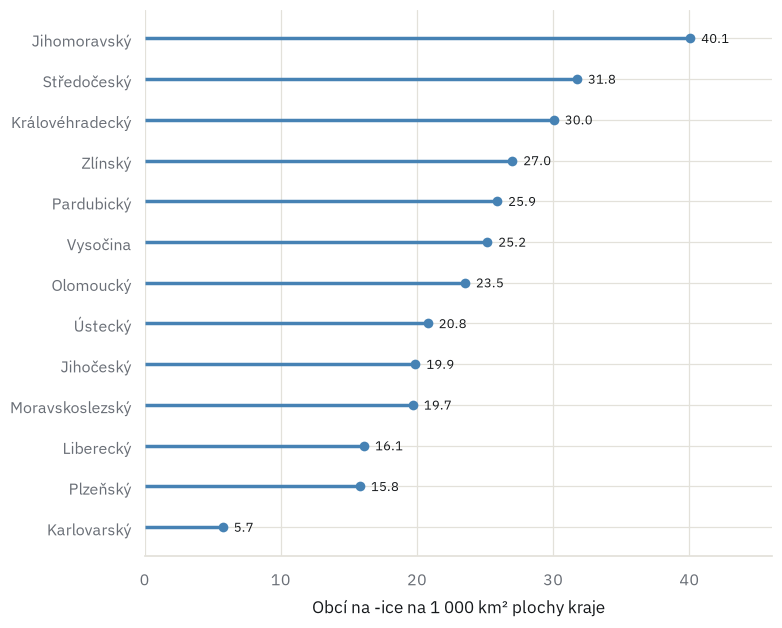

In [6]:
areas = data.load_kraj_areas()
fig = viz.plot_density_by_kraj(df, areas)
viz.save_fig(fig, "13_density_by_kraj")

## 4. Citlivost prostorové autokorelace na volbě k

`moran_binary_test` (nb08) používá k=6 sousedů bez dalšího zdůvodnění v
textu — k=6 je běžná defaultní hodnota pro k-NN prostorové váhy (dost
sousedů na stabilní odhad, dost málo na to, aby "sousedství" zůstalo
lokální), ne hodnota z konkrétní citace. Tenhle test ověří, že na přesné
volbě nezáleží: pokud I zůstává kladné a permutačně významné napříč
k=4..20, závěr článku není artefakt k=6.

In [7]:
k_result = viz.k_sensitivity_test(df, k_values=range(4, 21, 2), permutations=999)
k_result

C:\Users\dobes\Documents\UniversityCodingProject\NewFunnyProjects\GeoGram_sufix-ice\.venv\Lib\site-packages\libpysal\weights\distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)
C:\Users\dobes\Documents\UniversityCodingProject\NewFunnyProjects\GeoGram_sufix-ice\.venv\Lib\site-packages\libpysal\weights\distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


,k,moran_I,p_sim
0,4,0.120429,0.001
1,6,0.116169,0.001
2,8,0.106485,0.001
3,10,0.101206,0.001
4,12,0.094369,0.001
5,14,0.090574,0.001
6,16,0.084534,0.001
7,18,0.083265,0.001
8,20,0.078035,0.001


WindowsPath('C:/Users/dobes/Documents/UniversityCodingProject/NewFunnyProjects/GeoGram_sufix-ice/assets/img/geogram/13_k_sensitivity.svg')

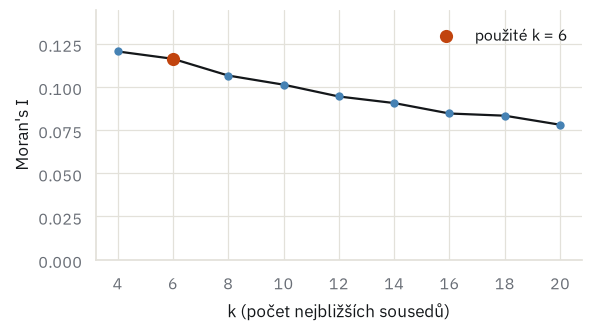

In [8]:
fig = viz.plot_k_sensitivity(k_result, chosen_k=6)
viz.save_fig(fig, "13_k_sensitivity")

## 5. LISA mapa s hranicí ČR

Přegeneruje `08_lisa_map.png` (nb08) — beze změny stylu, jen čerstvý běh.
Zkoušel jsem k tomu i hranici ČR pod body (`plot_lisa_map(..., boundary=...)`,
hranice ze zjednodušeného veřejného GeoJSON), ale vizuálně to nesedělo — na
web jde verze bez hranice, varianta s hranicí (`08_lisa_map_with_boundary.png`)
zůstává jen pro mou vlastní referenci.

C:\Users\dobes\Documents\UniversityCodingProject\NewFunnyProjects\GeoGram_sufix-ice\.venv\Lib\site-packages\libpysal\weights\distance.py:164: UserWarning: The weights matrix is not fully connected: 
 There are 2 disconnected components.
  W.__init__(self, neighbors, id_order=ids, **kwargs)


WindowsPath('C:/Users/dobes/Documents/UniversityCodingProject/NewFunnyProjects/GeoGram_sufix-ice/assets/img/geogram/08_lisa_map_with_boundary.png')

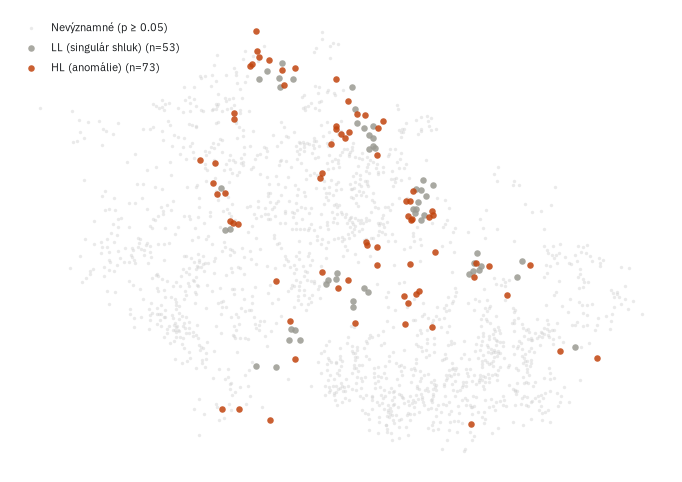

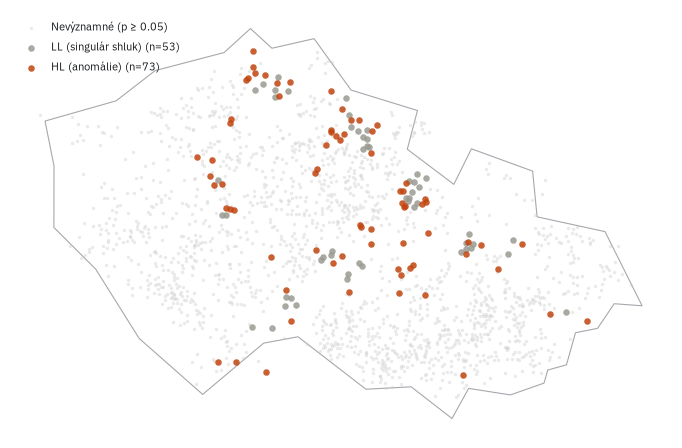

In [9]:
gdf, ml = viz.moran_local_test(df, k=6, permutations=9999, seed=42)

# Web verze (bez hranice — pro clanek, hranice "se nepovedla" vizualne)
fig = viz.plot_lisa_map(gdf, alpha=0.05)
viz.save_fig(fig, "08_lisa_map", fmt="png")

# Varianta s hranici CR pro moji vlastni referenci, samostatny soubor
# (nepřepisuje 08_lisa_map.png, ktery pouziva web)
boundary = data.load_cz_boundary()
fig_b = viz.plot_lisa_map(gdf, alpha=0.05, boundary=boundary)
viz.save_fig(fig_b, "08_lisa_map_with_boundary", fmt="png")